## Introduction

This is my personal implementation of Andrej Karpathy's zero to hero neural network series. All credits go to the original author.
In the previous notebook (BasicLanguageModelling), we implemented basic bigrams and trigrams using very basic (1 or 2 layer) neural network. Here, we expand the neural network to be more complex and sophisticated (called MultiLayerPerceptrons) so that we an make more accurate predictions with a larger context size.

In [3]:
# preparing the datatset
with open('brainrot_corpus.txt','r') as f:
    data = f.read()
words = data.split()
words = [w.lower() for w in words]
words[:5]

['crashout', 'karen:', 'bruh,', "it's", 'giving']

In [4]:
chars = list(set(''.join(words)))
len(chars)

40

In [7]:
itos = {i:s for i,s in enumerate(chars)}
stoi = {s:i for i,s in enumerate(chars)}

i = stoi['.']
stoi[itos[0]] = i
stoi['.'] = 0

itos[i] = itos[0]
itos[0] = '.'

itos[0], stoi['.'],itos[i],stoi[itos[i]],i

('.', 0, 'c', 34, 34)

In [14]:
# visualizing longer context sizes
context_size = 3

for w in words[:3]:
    chs = list(w) + ['.']
    print(w)
    block = [0]*context_size
    for i in range(len(chs)):
        ix = stoi[chs[i]]
        print(''.join([itos[i] for i in block])," ---> ",chs[i])
        block = block[1:] + [ix]
    print('\n')

crashout
...  --->  c
..c  --->  r
.cr  --->  a
cra  --->  s
ras  --->  h
ash  --->  o
sho  --->  u
hou  --->  t
out  --->  .


karen:
...  --->  k
..k  --->  a
.ka  --->  r
kar  --->  e
are  --->  n
ren  --->  :
en:  --->  .


bruh,
...  --->  b
..b  --->  r
.br  --->  u
bru  --->  h
ruh  --->  ,
uh,  --->  .




In [17]:
# preparing the entire dataset now with context as input and next char as output
import torch

X,y = [],[]
for w in words:
    chs = list(w) + ['.']
    block = [0]*context_size
    for i in range(len(chs)):
        ix = stoi[chs[i]]
        X.append(block)
        y.append(ix)
        block = block[1:] + [ix]
X = torch.tensor(X)
y = torch.tensor(y)
X.shape,X.dtype,y.shape,y.dtype

(torch.Size([1110057, 3]), torch.int64, torch.Size([1110057]), torch.int64)

## Embedding Table

In the previous models, we were converting each character to a onehot encoding and multiplying to the weights directly. But just 1 list of 0s and 1s is not enough to encode information about context so we need embeddings meaning each character is represented by a list of float (length of this list is called the dimension of the embedding). In our case we can use 3 dimensional embeddings, meaning each character is represented by a list of 3 floats such that those floats can give us information about the position and meaning when they interact with each other. Note: Having a separate embedding matrix followed by weights of the first layer without any non-linearity (which we are going to do) is the same as having 1 matrix which is the product of the other 2 but we are still going to keep them separate for our own clarity even though it doesn't make any difference between having 2 different matrices or 1 matrix for the embedding and the first layer weights.

In [44]:
n = len(chars)
C = torch.randn((n,3),requires_grad=True) # this is a character level embedding table, n rows and 2 cols: 2 floats for each of the n chars

In [45]:
X.shape, C.shape

(torch.Size([1110057, 3]), torch.Size([40, 3]))

In [46]:
'''
X has our context matrix, meaning input context which is a list of 3 chars and C has representation of each char
if we want embedding of the 5th char, we do C[5] giving us the 5th row same as if we give onehot encoding of 5th char
doing C[[5,6,7]] gives a list of embeddings of 5th,6th,7th chars so this is the same as providing a list of 3 chars as context and getting
the list of their embeddings i.e same as doing C[X[i]] giving us a list of embeddings of each char in that input context or we can say the 
embedding of the input itself. But we want to get the embeddings of all the input context blocks in X in one go to make our training 
embedding table so we can just do:
'''
emb = C[X]
emb.shape

torch.Size([1110057, 3, 3])

Hence as we can see above our embedding training table is of shape $(m,c,e)$ where $m$ is the number of blocks/inputs in X, $c$ is our context size and $e$ is our embedding size. One matrix of $(c,e)$ is the embedding of that context block (made by concatenating embeddings of all chars) and for our training dataset, we have $m$ such matrices. Note: When we actually get the neural network, getting input of a word would just mean doing `C[w]` where `w` is the list of `stoi` values.

## Building Weights

Now we start building the first layer and connect it to the embeddings.

In [47]:
W1 = torch.randn((9,100),requires_grad=True) 
b1 = torch.randn((1,100),requires_grad=True)

The reason we have 9 inputs for each of the 100 neurons in the above layers is because we have each block of context have 3 chars and each char represented by 3 floats so each piece of input context block is a 3x3 matrix but we'll have to reduce dimensionality to make each block as a single list of 3 numbers so that each word can be passed as input. We can change shape of tensor easily using `torch.view()` because internally all numbers are stored as a single sequence of bytes and in pytorch we can interpret as being different dimensions.

In [50]:
activations = emb.view(-1,9) @ W1 + b1# we use -1 to allow pytorch to infer that dimension; we only care that second dim is 3

In [51]:
activations.shape

torch.Size([1110057, 100])

Even though `emb.view(-1,9) @ W1` had shape $(m,100)$ and `b1` was $(1,100)$, we are able to add bias because internally pytorch makes $m$ copies of b1 and stacks them to make a matrix of the same shape. This is possible due to broadcasting rules

In [52]:
W2 = torch.randn((100,n),requires_grad=True)  # n outputs because we need to generate n probs for each char
b2 = torch.randn((1,n),requires_grad=True)

## Loss

In previous neural nets, we used negative log loss which we can use here but we're going to be using cross entropy loss which is numerically safer. The reason is when we exponentiate logits, any large positive values of logits become infinity which is problematic unlike large negative values which become 0. However, if we add/subtract a constant from every logits, the probs would be exactly the same as before becuase shifting all numbers by a constant doesn't matter since dividing them by their mean gives the same value (which depends on their relative differences rather than their literal values) but this process is better because subtracting logits by the max logit value ensures there are no large positive values so exponentiation happens perfectly while keeping the probabilities the same. This is done by pytorch automatically while calculating cross entropy.

In [53]:
import torch.nn.functional as F
# now we can use F.cross_entropy(logits,y)

In [54]:
parameters = [C,W1,b1,W2,b2]

In [55]:
sum(p.nelement() for p in parameters) # Total numbers/parameters in weights,biases and embeddings

5160

## Training 

Now we can start training on the entire dataset.

In [57]:
for _ in range(100): # 100 iterations
    # forward pass
    emb = C[X]
    layer1 = torch.tanh(emb.view(-1,9) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,y) # cross entropy automatically calculates probabilities
    # print(loss.item())
    # bakward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.1*p.grad
print(loss.item())

2.5667319297790527


As you can see above, loss is similar to what we had with bigrams and trigrams but its nowhere close to 0 because while it can predict next alphabet based on previous 3, as you may recall above, for every word a block of `[0,0,0]` is predicting something different entirely for every word. Prediction after '.' is causing the above error. Another problem we have: 100 iterations is taking a lot of time and increasing iterations is also a valid way of increasing accuracy.

## Minibatches

Now we can solve the above problems, especially the time one, using minibatches. Instead of training the params on the entire dataset each iteration, we can randomly take batches of let's say 50 context blocks and train the net on those 50 each iteration. This way each iteration is much faster and so we can have many iterations.

In [59]:
C = torch.randn((n,3),requires_grad=True)
W1 = torch.randn((9,100),requires_grad=True) 
b1 = torch.randn((1,100),requires_grad=True)
W2 = torch.randn((100,n),requires_grad=True)  
b2 = torch.randn((1,n),requires_grad=True)
parameters = [C,W1,b1,W2,b2]

for _ in range(1000):
    # getting minibatch
    ix = torch.randint(0,X.shape[0],(50,))
    # forward pass
    emb = C[X[ix]]
    layer1 = torch.tanh(emb.view(-1,9) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,y[ix])
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.1*p.grad
print(loss.item())

2.1072146892547607


This was much faster and the loss is not slightly better. We can still improve loss by choosing a better learning rate unlike till now which we have been just choosing based on vibes.

## Choosing Learning Rate

One way we can determine a good learning rate is taking many candidate learning rates from a decent range and monitoring the change in loss and select the one in which loss change is the most stable. Now if change lr at each iteration and track loss, the rates that appear in earlier iterations will have a worse loss value and ones appearing in later iterations will have a better loss. But we need to monitor the change in loss values not the the value itself so instead of comparing loss values to the learning rate values, we compare it to learning rate exponents ie the exponent of 10. If we have a range of exponents of 10, plotting it against loss values will give us the stability and relative difference. 

In [60]:
lre = torch.linspace(-3,0,1000) # 1000 values between -3 (0.001) and 0 (1)
lrs = 10**lre

In [61]:
lres = []
lossi = []
C = torch.randn((n,3),requires_grad=True)
W1 = torch.randn((9,100),requires_grad=True) 
b1 = torch.randn((1,100),requires_grad=True)
W2 = torch.randn((100,n),requires_grad=True)  
b2 = torch.randn((1,n),requires_grad=True)
parameters = [C,W1,b1,W2,b2]

for i in range(1000):
    # getting minibatch
    ix = torch.randint(0,X.shape[0],(50,))
    # forward pass
    emb = C[X[ix]]
    layer1 = torch.tanh(emb.view(-1,9) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,y[ix])
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -lrs[i]*p.grad
    lres.append(lre[i])
    lossi.append(loss.item())
print(loss.item())

5.243210315704346


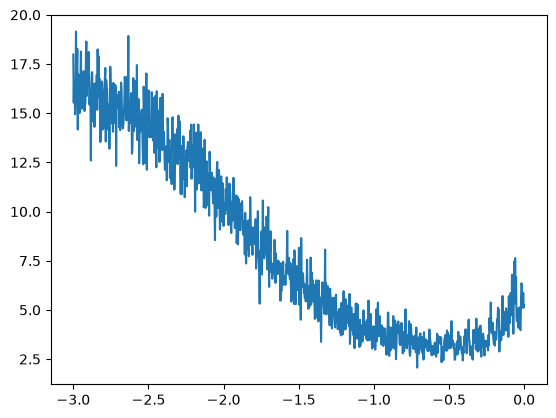

In [62]:
import matplotlib.pyplot as plt
plt.plot(lres,lossi)
plt.show()

We see the curve hit the minimum against -0.5 so that is our best learning rate

In [64]:
C = torch.randn((n,3),requires_grad=True)
W1 = torch.randn((9,100),requires_grad=True) 
b1 = torch.randn((1,100),requires_grad=True)
W2 = torch.randn((100,n),requires_grad=True)  
b2 = torch.randn((1,n),requires_grad=True)
parameters = [C,W1,b1,W2,b2]

for _ in range(10000):
    # getting minibatch
    ix = torch.randint(0,X.shape[0],(50,))
    # forward pass
    emb = C[X[ix]]
    layer1 = torch.tanh(emb.view(-1,9) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,y[ix])
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.5*p.grad
print(loss.item())

1.4235600233078003


When we fintune the model, we can use lr = learning rate / 10 of our optimal lr.

## Splitting the dataset

Using the methods we have, we have achieved a loss much better than our bigram/trigram. This is most likely due to overfitting which is the mdoel memorizing words and examples from the training data. To check and avoid this, we can split our dataset into 3: training data, dev/validation data and test data. **Training data** is used to train the parameters (weights, biases), **dev/validation data** is used to evaluate the model and tune our hyperparameters (learning rate, size of the layer like number of neurons etc) and finally at last we **test data** to get a final evaluation of the model, we use test data really sparingly.

In [65]:
import random

random.seed(42)
random.shuffle(words)

def build_dataset(words):
    X,y = [],[]
    for w in words:
        chs = list(w) + ['.']
        block = [0]*context_size
        for i in range(len(chs)):
            ix = stoi[chs[i]]
            X.append(block)
            y.append(ix)
            block = block[1:] + [ix]
    X = torch.tensor(X)
    y = torch.tensor(y)
    return X,y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
train_X,train_y = build_dataset(words[:n1]) # 80%
val_X, val_y = build_dataset(words[n1:n2]) # 10%
test_X,test_y = build_dataset(words[n2:]) # 10%

In [66]:
# first training on training data
C = torch.randn((n,3),requires_grad=True)
W1 = torch.randn((9,100),requires_grad=True) 
b1 = torch.randn((1,100),requires_grad=True)
W2 = torch.randn((100,n),requires_grad=True)  
b2 = torch.randn((1,n),requires_grad=True)
parameters = [C,W1,b1,W2,b2]

for _ in range(10000):
    # getting minibatch
    ix = torch.randint(0,train_X.shape[0],(50,))
    # forward pass
    emb = C[train_X[ix]]
    layer1 = torch.tanh(emb.view(-1,9) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,train_y[ix])
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.5*p.grad
print(loss.item())

1.3703173398971558


In [68]:
# now evaluating it on validation data
emb = C[val_X]
layer1 = torch.tanh(emb.view(-1,9) @ W1 + b1)
logits = layer1 @ W2 + b2
loss = F.cross_entropy(logits,val_y)
print(loss.item())

1.177520513534546


If validation loss is close to training loss, it means neither under nor overfit. Our model is small so it either does this or underfit. Large models overfit which leads to val loss being much higher than train loss. In our case, we can reduce loss using multiple ways: 
1) Increase embedding dimensions
2) Increase number of neurons in hidden layer
3) Change the learning rate and much more... \
\
Since we have already optimised for learning rate we can do the other 2 and then check the loss. Doing this after getting val loss is called hyperparameter tuning.

In [72]:
C = torch.randn((n,10),requires_grad=True) # now 10 embedding dimensions
W1 = torch.randn((30,300),requires_grad=True) 
b1 = torch.randn((1,300),requires_grad=True) # 300 neurons in hidden layer
W2 = torch.randn((300,n),requires_grad=True)  
b2 = torch.randn((1,n),requires_grad=True)
parameters = [C,W1,b1,W2,b2]
stepi,lossi = [],[]


0.85036301612854


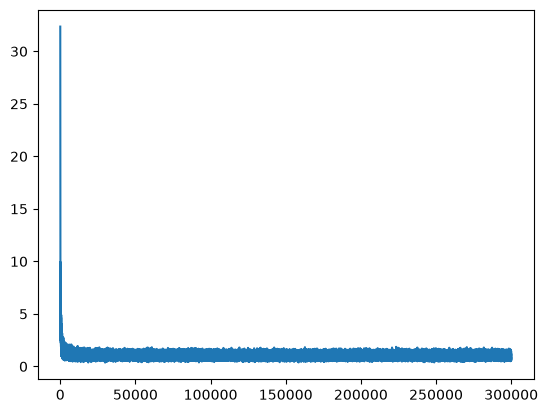

In [73]:
for i in range(300000): # 300k  iterations
    # getting minibatch
    ix = torch.randint(0,train_X.shape[0],(50,))
    # forward pass
    emb = C[train_X[ix]]
    layer1 = torch.tanh(emb.view(-1,30) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,train_y[ix])
    stepi.append(i)
    lossi.append(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.05*p.grad
        
print(loss.item())
plt.plot(stepi,lossi)
plt.show()

As you can see, the loss has improved. Now we can evaluate it on val set.

In [75]:
emb = C[val_X]
layer1 = torch.tanh(emb.view(-1,30) @ W1 + b1)
logits = layer1 @ W2 + b2
loss = F.cross_entropy(logits,val_y)
print(loss.item())

1.0088695287704468


Finally, we can also tune the model on the val set by using a learning rate = lr/10 to improve it a little more.

0.9292014837265015


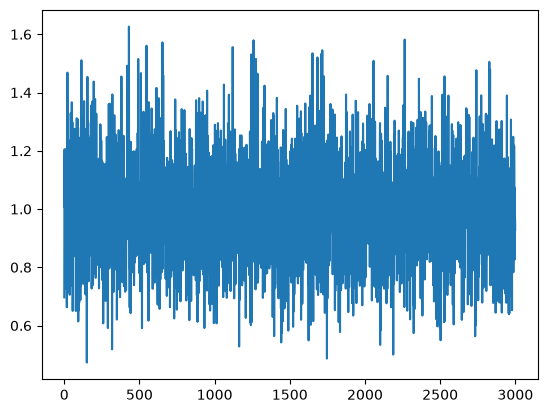

In [76]:
stepi,lossi = [],[]
for i in range(3000): # 3k iterations
    # getting minibatch
    ix = torch.randint(0,val_X.shape[0],(50,))
    # forward pass
    emb = C[val_X[ix]]
    layer1 = torch.tanh(emb.view(-1,30) @ W1 + b1)
    logits = layer1 @ W2 + b2
    loss = F.cross_entropy(logits,val_y[ix])
    stepi.append(i)
    lossi.append(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.005*p.grad # smaller learning rate
        
print(loss.item())
plt.plot(stepi,lossi)
plt.show()

Validation loss further reduced. Finally evaluating it on the testing set.

In [77]:
emb = C[test_X]
layer1 = torch.tanh(emb.view(-1,30) @ W1 + b1)
logits = layer1 @ W2 + b2
loss = F.cross_entropy(logits,test_y)
print(loss.item())

1.0005271434783936


## Sampling

Now we can start sampling from our model.

In [78]:
for _ in range(20): # generating 20 words
    out = []
    block = [0]*context_size
    while True:
        emb = C[torch.tensor(block)]
        layer1 = torch.tanh(emb.view(-1,30) @ W1 + b1)
        logits = layer1 @ W2 + b2
        probs = F.softmax(logits,dim=1)
        ix = torch.multinomial(probs,num_samples=1).item()
        block = block[1:] + [ix]
        out.append(ix)
        if ix==0:
            break
    print(''.join([itos[c] for c in out]))

the.
crocodilo.
is.
said.
hout.
rizzlertified.
ohio.
cap.
beyone.
moment.
the.
said.
zone.
you.
even:.
goofinator.
againrothere.
major.
goofinator.
mewing.
